# Rigidez Numérica em Redes Neurais Biológicas: O Conectoma da *Drosophila melanogaster* como Estudo de Caso

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/brunoabreuco/drosophila-connectome-stiffness/blob/main/drosophila_connectome_stiffness.ipynb)

**Instituição:** Universidade Federal de São Paulo (UNIFESP) — Instituto de Ciência e Tecnologia (ICT / SJC)  
**Disciplina:** Cálculo Numérico  
**Repositório:** [`brunoabreuco/drosophila-connectome-stiffness`](https://github.com/brunoabreuco/drosophila-connectome-stiffness)

### Integrantes do Grupo
- **Bruno de Abreu Correia**
- **Felipe Scarpin Mesquita**
- **Guilherme Pombo Takayama Augusto**
- **Júlia Cristina Perroni de Martini Pereira**

---

### Visão Geral e Objetivos do Notebook

Este notebook investiga o fenômeno de **rigidez numérica (*numerical stiffness*)** emergente da heterogeneidade topológica de redes neurais biológicas reais, utilizando dados conectômicos de microscopia eletrônica do cérebro central da mosca-da-fruta (*Drosophila melanogaster*, dataset **Janelia Hemibrain v1.2.1** via plataforma **NeuPrint**):

1. **Parte 1 — Aquisição do Conectoma e Construção do Sistema de EDOs (Objetivo a):** Extração e limpeza da matriz de conectividade sináptica $W$ da **Ponte Protocerebral (*Protocerebral Bridge*, `PB`)**, identificação biológica dos neurônios *hubs* ($\Delta 7$ e $\text{LPsP}$) e formulação do Problema de Valor Inicial (PVI) linear $\frac{d\mathbf{x}}{dt} = A\mathbf{x}$.
2. **Parte 2 — Análise Espectral, Condicionamento e Rigidez (Objetivo b):** Localização dos autovalores via Discos de Gershgorin, razão de rigidez $S(A)$, número de condicionamento $\kappa_2(A)$ e passo crítico explícito $h_{\text{crit}}$.
3. **Parte 3 — Integradores Numéricos e Validação Analítica em $N = 20$ (Objetivo d):** Validação dos métodos de Euler Explícito, RK4, Euler Implícito e Trapézio Implícito (Crank-Nicolson) contra a solução analítica exata via exponencial de matriz ($e^{At}\mathbf{x}_0$).
4. **Parte 4 — Estabilidade e Custo Computacional em $N = 120$ (Objetivo c):** Demonstração da explosão numérica dos métodos explícitos para $h > h_{\text{crit}}$ e ganho de desempenho com pré-fatoração $LU$ nos métodos implícitos A-estáveis.
5. **Parte 5 — Controle Sintético de Erdős–Rényi (Objetivo e):** Comparação da rigidez biológica contra grafos aleatórios de Erdős–Rényi de mesma dimensão e densidade sináptica.

---

## Parte 1 — Aquisição e Limpeza do Conectoma e Construção da Matriz $A$ (Objetivo a)

### 1.1. Contexto Biológico: O Circuito de Bússola Interna (*Protocerebral Bridge* — `PB`)

O dataset **Hemibrain v1.2.1** (Scheffer et al., 2020; Hulse et al., 2021), disponibilizado pelo Howard Hughes Medical Institute (Janelia Research Campus) através da API **NeuPrint**, reconstrói em nível sináptico individual cerca de $25.000$ neurônios do cérebro central da *Drosophila melanogaster*.

Selecionamos como região funcional de estudo a **Ponte Protocerebral (*Protocerebral Bridge*, `PB`)**, uma estrutura central do **Complexo Central (*Central Complex*, `CX`)** responsável pelo processamento de orientação espacial e manutenção da bússola interna (*head-direction ring attractor*) do inseto. A escolha da `PB` é ideal tanto do ponto de vista neurobiológico quanto numérico:

- **Presença de Super-*Hubs* Inibitórios e Integradores Globais:** A `PB` abriga os interneurônios locais glutamatérgicos/inibitórios **$\Delta 7$ (`Delta7`)** e os neurônios integradores bilaterais **`LPsP`**, que se ramificam por todos os glomérulos da ponte, acumulando milhares de sinapses de entrada e saída.
- **Neurônios Colunares de Bússola e Velocidade Angular:** Os neurônios **`EPG`** (*Ellipsoid Body–Protocerebral Bridge–Gall*) e **`PEN_a` / `PEN_b`** formam conexões mais seletivas e esparsas entre glomérulos específicos.
- **Consequência para o Cálculo Numérico:** Essa coexistência entre neurônios globalmente conectados (*hubs*, que operam como modos dinâmicos ultra-rápidos — "lebres") e neurônios periféricos/colunares ("tartarugas") induz uma **severa separação de escalas de tempo** no sistema de EDOs.

---

### 1.2. Protocolo de Limpeza e Extração em Duas Etapas (Cypher / NeuPrint)

Para garantir reprodutibilidade rigorosa e evitar artefatos de reconstrução de microscopia eletrônica:

1. **Filtro de Qualidade (`status = 'Traced'`):** Excluímos fragmentos neurais não rastreados (`Orphan`, `Assign`, `Unimportant`), mantendo exclusivamente neurônios morfologicamente validados (`n.status = "Traced"`) que arborizam na região `PB` (`n.PB = true`).
2. **Remoção de Autossinapses ($W_{ii} = 0$):** Conexões reflexivas (autapses, `pre.bodyId = post.bodyId`) são descartadas tanto na consulta Cypher quanto explicitamente na diagonal principal da matriz (`np.fill_diagonal(W, 0.0)`).
3. **Ranqueamento por Grau Sináptico Total na ROI e Seleção Top-$N$:**
   - Todos os $823$ neurônios `Traced` interconectados na `PB` ($51.859$ conexões direcionadas) são ordenados pelo peso sináptico total ($d_i^{\text{in, PB}} + d_i^{\text{out, PB}}$).
   - **Sub-rede Principal ($N = 120$):** Selecionamos os **Top 120 neurônios mais conectados**, verificando que todo neurônio pertence ao componente ativo ($\min_i (d_i + d_i^{\text{out}}) = 117 > 0$).
   - **Subsistema de Validação Analítica ($N = 20$):** Recorte dos **Top 20 neurônios** do mesmo ranking para validação contra a exponencial de matriz exata $\mathbf{x}(t) = e^{At}\mathbf{x}_0$.
4. **Convenção Direcional de Fluxo ($j \to i$):**
   $$W_{ij} = w(j \to i) \ge 0 \quad (\text{sinapses do neurônio pré-sináptico } j \text{ para o pós-sináptico } i)$$
   Assim, no produto matricial $W\mathbf{x}$, a linha $i$ soma os estímulos recebidos pelo neurônio $i$: $\sum_{j=1}^N W_{ij} x_j$, e a soma da linha $i$ define a **condutância sináptica total de entrada** $d_i = \sum_{j=1}^N W_{ij}$.

---

### 1.3. Formulação Matemática do Sistema Linear de EDOs

A dinâmica da atividade neural $\mathbf{x}(t) = [x_1(t), \dots, x_N(t)]^T \in \mathbb{R}^N$ no intervalo $t \in [0, T]$ é governada pelo Problema de Valor Inicial (PVI):

$$\begin{cases} \dfrac{d\mathbf{x}(t)}{dt} = A\mathbf{x}(t), & t \in [0, T] \\[6pt] \mathbf{x}(0) = \mathbf{x}_0 \end{cases}$$

Implementamos duas formulações canônicas para a matriz de estado $A \in \mathbb{R}^{N \times N}$ que garantem estabilidade assintótica ($\operatorname{Re}(\lambda_k(A)) < 0, \, \forall k$):

1. **Formulação Principal — Operador Laplaciano Amortecido (Modelo de Condutância Sináptica):**
   $$A = -\epsilon I - D_{\text{in}} + W, \quad D_{\text{in}} = \operatorname{diag}(d_1, d_2, \dots, d_N), \quad d_i = \sum_{j=1}^{N} W_{ij}$$
   onde $\epsilon = 1{,}0\text{ s}^{-1}$ representa a taxa basal de vazamento passivo de membrana. Pelo **Teorema dos Discos de Gershgorin**, cada linha $i$ gera um disco centrado em $A_{ii} = -(\epsilon + d_i)$ com raio $R_i = \sum_{j \neq i} |A_{ij}| = d_i$, garantindo analiticamente que todos os autovalores situam-se no semiplano esquerdo aberto:
   $$-(\epsilon + 2 d_{\max}) \le \operatorname{Re}(\lambda_k(A)) \le -\epsilon < 0$$
2. **Formulação Alternativa — Deslocamento Espectral Uniforme (*Spectral Shift*):**
   $$A = -\gamma I + W, \quad \gamma = \max_{1 \le k \le N} \operatorname{Re}(\lambda_k(W)) + \epsilon$$

In [1]:
# Célula 1: Importações, Configuração de Ambiente e Funções de Aquisição (CSV / GitHub / NeuPrint API)
import csv
import gzip
import json
import os
import ssl
import time
import urllib.request
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import numpy as np

try:
    import certifi
    SSL_CTX = ssl.create_default_context(cafile=certifi.where())
except ImportError:
    SSL_CTX = ssl.create_default_context()

NEUPRINT_CUSTOM_URL = "https://neuprint.janelia.org/api/custom/custom"
DEFAULT_DATASET = "hemibrain:v1.2.1"
DEFAULT_ROI = "PB"
GITHUB_RAW_BASE = (
    "https://raw.githubusercontent.com/brunoabreuco/drosophila-connectome-stiffness/main/data"
)


def load_env_token(env_path: str | Path = ".env") -> str | None:
    """
    Busca o token NEUPRINT_TOKEN de variável de ambiente, arquivo .env local
    ou Secrets do Google Colab (google.colab.userdata). Nunca expõe o token.
    """
    token = os.environ.get("NEUPRINT_TOKEN", "").strip()
    if token:
        return token

    env_file = Path(env_path)
    if env_file.exists():
        for line in env_file.read_text(encoding="utf-8").splitlines():
            stripped = line.strip()
            if not stripped or stripped.startswith("#"):
                continue
            if stripped.startswith("NEUPRINT_TOKEN="):
                val = stripped.split("=", 1)[1].strip().strip('"').strip("'")
                if val:
                    return val

    try:
        from google.colab import userdata  # type: ignore
        val = userdata.get("NEUPRINT_TOKEN")
        if val:
            return val.strip()
    except Exception:
        pass

    return None


def run_cypher_query(
    cypher: str,
    token: str,
    dataset: str = DEFAULT_DATASET,
    timeout: int = 45,
) -> dict:
    """Executa consulta Cypher na API REST do NeuPrint com compressão gzip."""
    payload = json.dumps({"cypher": cypher, "dataset": dataset}).encode("utf-8")
    req = urllib.request.Request(
        NEUPRINT_CUSTOM_URL,
        data=payload,
        headers={
            "Authorization": f"Bearer {token}",
            "Content-Type": "application/json",
            "Accept": "application/json",
            "Accept-Encoding": "gzip",
        },
        method="POST",
    )
    with urllib.request.urlopen(req, timeout=timeout, context=SSL_CTX) as resp:
        raw = resp.read()
        if resp.info().get("Content-Encoding") == "gzip":
            raw = gzip.decompress(raw)
        return json.loads(raw.decode("utf-8"))


def fetch_roi_subnetwork(
    token: str,
    roi: str = DEFAULT_ROI,
    n_main: int = 120,
    n_small: int = 20,
    dataset: str = DEFAULT_DATASET,
) -> dict:
    """
    Extrai ao vivo da API NeuPrint os Top N=120 e N=20 neurônios 'Traced' da ROI (PB)
    em duas consultas Cypher otimizadas e constrói W na convenção W_ij = peso(j -> i).
    """
    start_time = time.perf_counter()

    # Etapa 1: Ranking de grau sináptico total dentro da ROI no servidor Neo4j
    cypher_rank = f"""
    MATCH (n:Neuron {{`{roi}`: true}})-[c:ConnectsTo]-(m:Neuron {{`{roi}`: true}})
    WHERE n.status = "Traced" AND m.status = "Traced" AND n.bodyId <> m.bodyId
    RETURN n.bodyId AS bodyId, n.type AS type, n.instance AS instance,
           sum(c.weight) AS total_roi_weight, count(c) AS num_roi_edges
    ORDER BY total_roi_weight DESC, bodyId ASC
    """
    rank_rows = run_cypher_query(cypher_rank, token=token, dataset=dataset)["data"]
    top_rows = rank_rows[:n_main]
    top_ids = [int(row[0]) for row in top_rows]

    # Etapa 2: Conexões direcionadas no subgrafo induzido pelos Top N neurônios
    ids_csv = ", ".join(str(body_id) for body_id in top_ids)
    cypher_edges = f"""
    MATCH (pre:Neuron)-[c:ConnectsTo]->(post:Neuron)
    WHERE pre.bodyId IN [{ids_csv}] AND post.bodyId IN [{ids_csv}] AND pre.bodyId <> post.bodyId
    RETURN pre.bodyId AS pre_id, post.bodyId AS post_id, c.weight AS weight
    """
    edge_rows = run_cypher_query(cypher_edges, token=token, dataset=dataset)["data"]

    id_to_idx = {body_id: idx for idx, body_id in enumerate(top_ids)}
    W_main = np.zeros((n_main, n_main), dtype=np.float64)
    for pre_id, post_id, weight in edge_rows:
        col_j = id_to_idx[int(pre_id)]   # pré-sináptico (coluna j)
        row_i = id_to_idx[int(post_id)]  # pós-sináptico (linha i)
        W_main[row_i, col_j] += float(weight)

    np.fill_diagonal(W_main, 0.0)
    W_small = W_main[:n_small, :n_small].copy()
    np.fill_diagonal(W_small, 0.0)

    d_in = np.sum(W_main, axis=1)
    d_out = np.sum(W_main, axis=0)
    neurons = [
        {
            "index": idx,
            "bodyId": int(row[0]),
            "type": str(row[1] or "Unknown"),
            "instance": str(row[2] or "Unknown"),
            "d_in": int(round(d_in[idx])),
            "d_out": int(round(d_out[idx])),
            "total_weight": int(round(d_in[idx] + d_out[idx])),
            "total_roi_weight": int(row[3]),
        }
        for idx, row in enumerate(top_rows)
    ]
    return {
        "W_N120": W_main,
        "W_N20": W_small,
        "neurons_N120": neurons,
        "roi": roi,
        "dataset": dataset,
        "total_traced_connected_in_roi": len(rank_rows),
        "total_directed_edges_in_roi": sum(int(row[4]) for row in rank_rows) // 2,
        "elapsed_seconds": time.perf_counter() - start_time,
    }


def save_subnetwork_csv(data: dict, data_dir: str | Path = "data") -> tuple[Path, Path, Path]:
    """Salva as matrizes W_real_N120.csv, W_real_N20.csv e a tabela neurons_N120.csv em `data/`."""
    out_dir = Path(data_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    path_w120 = out_dir / "W_real_N120.csv"
    path_w20 = out_dir / "W_real_N20.csv"
    path_neurons = out_dir / "neurons_N120.csv"

    np.savetxt(path_w120, data["W_N120"], delimiter=",", fmt="%.0f")
    np.savetxt(path_w20, data["W_N20"], delimiter=",", fmt="%.0f")

    fieldnames = [
        "index", "bodyId", "type", "instance",
        "d_in", "d_out", "total_weight", "total_roi_weight",
    ]
    with open(path_neurons, "w", newline="", encoding="utf-8") as file_obj:
        writer = csv.DictWriter(file_obj, fieldnames=fieldnames)
        writer.writeheader()
        for row in data["neurons_N120"]:
            writer.writerow(row)
    return path_w120, path_w20, path_neurons


def load_connectome_data(
    data_dir: str | Path = "data",
    github_raw_base: str = GITHUB_RAW_BASE,
    token: str | None = None,
) -> tuple[np.ndarray, np.ndarray, list[dict]]:
    """
    Carrega os dados do conectoma priorizando:
      1) Arquivos CSV pré-extraídos em `data/` (execução local instantânea);
      2) Extração ao vivo via NeuPrint API se `token` for fornecido;
      3) Download automático do repositório GitHub caso executado no Google Colab sem arquivos locais.
    """
    out_dir = Path(data_dir)
    path_w120 = out_dir / "W_real_N120.csv"
    path_w20 = out_dir / "W_real_N20.csv"
    path_neurons = out_dir / "neurons_N120.csv"

    if not (path_w120.exists() and path_w20.exists() and path_neurons.exists()):
        if token:
            data = fetch_roi_subnetwork(token=token)
            save_subnetwork_csv(data, data_dir=out_dir)
            return data["W_N120"], data["W_N20"], data["neurons_N120"]

        out_dir.mkdir(parents=True, exist_ok=True)
        for filename in ["W_real_N120.csv", "W_real_N20.csv", "neurons_N120.csv"]:
            target = out_dir / filename
            if not target.exists():
                url = f"{github_raw_base}/{filename}"
                req = urllib.request.Request(url, headers={"User-Agent": "UNIFESP-CN-Colab/1.0"})
                with urllib.request.urlopen(req, timeout=30, context=SSL_CTX) as resp:
                    target.write_bytes(resp.read())

    W_n120 = np.loadtxt(path_w120, delimiter=",", dtype=np.float64)
    W_n20 = np.loadtxt(path_w20, delimiter=",", dtype=np.float64)
    with open(path_neurons, "r", encoding="utf-8") as file_obj:
        neurons = [
            {
                "index": int(row["index"]),
                "bodyId": int(row["bodyId"]),
                "type": row["type"],
                "instance": row["instance"],
                "d_in": int(float(row["d_in"])),
                "d_out": int(float(row["d_out"])),
                "total_weight": int(float(row["total_weight"])),
                "total_roi_weight": int(float(row.get("total_roi_weight", row["total_weight"]))),
            }
            for row in csv.DictReader(file_obj)
        ]
    return W_n120, W_n20, neurons


print("Ambiente inicializado com sucesso (NumPy", np.__version__, "| Matplotlib", plt.matplotlib.__version__, ").")

Ambiente inicializado com sucesso (NumPy 2.5.3 | Matplotlib 3.11.2 ).

In [2]:
# Célula 2: Carregamento das Matrizes Reais (N = 120 e N = 20), Construção da Matriz A e Diagnóstico
def build_system_matrix(
    W: np.ndarray,
    epsilon: float = 1.0,
    mode: str = "laplacian",
) -> np.ndarray:
    """
    Constrói a matriz de estado A do sistema linear dx/dt = A x.
      - mode='laplacian': A = -epsilon * I - D_in + W, com D_in = diag(sum_j W_ij)
      - mode='shift':     A = -gamma * I + W, com gamma = max_k Re(lambda_k(W)) + epsilon
    """
    W_clean = np.array(W, dtype=np.float64, copy=True)
    np.fill_diagonal(W_clean, 0.0)
    n = W_clean.shape[0]
    identity = np.eye(n, dtype=np.float64)

    if mode == "laplacian":
        d_in = np.sum(W_clean, axis=1)
        return -epsilon * identity - np.diag(d_in) + W_clean
    elif mode == "shift":
        eigenvalues_W = np.linalg.eigvals(W_clean)
        gamma = float(np.max(np.real(eigenvalues_W))) + epsilon
        return -gamma * identity + W_clean
    else:
        raise ValueError("Invalid mode. Choose 'laplacian' or 'shift'.")


def compute_spectral_metrics(W: np.ndarray, A: np.ndarray) -> dict[str, float]:
    """Calcula métricas estruturais e espectrais da matriz de conectividade W e da matriz A."""
    n = W.shape[0]
    nnz = int(np.count_nonzero(W))
    total_entries = n * n
    sparsity_pct = 100.0 * (1.0 - nnz / total_entries)
    density_pct = 100.0 * (nnz / total_entries)

    d_in = np.sum(W, axis=1)
    d_out = np.sum(W, axis=0)
    active_weights = W[W > 0]

    eigenvalues = np.linalg.eigvals(A)
    real_abs = np.abs(np.real(eigenvalues))
    mod_abs = np.abs(eigenvalues)

    return {
        "N": float(n),
        "nnz": float(nnz),
        "total_entries": float(total_entries),
        "sparsity_pct": float(sparsity_pct),
        "density_pct": float(density_pct),
        "total_synapses": float(np.sum(W)),
        "d_in_min": float(np.min(d_in)),
        "d_in_max": float(np.max(d_in)),
        "d_in_mean": float(np.mean(d_in)),
        "d_in_median": float(np.median(d_in)),
        "d_out_min": float(np.min(d_out)),
        "d_out_max": float(np.max(d_out)),
        "w_max": float(np.max(W)),
        "w_mean_active": float(np.mean(active_weights)) if nnz > 0 else 0.0,
        "w_median_active": float(np.median(active_weights)) if nnz > 0 else 0.0,
        "lambda_re_min_abs": float(np.min(real_abs)),
        "lambda_re_max_abs": float(np.max(real_abs)),
        "lambda_mod_max": float(np.max(mod_abs)),
        "stiffness_ratio_S": float(np.max(real_abs) / np.min(real_abs)),
        "cond_2_A": float(np.linalg.cond(A, p=2)),
        "h_crit_euler": float(2.0 / np.max(mod_abs)),
        "h_crit_rk4": float(2.785293563405289 / np.max(mod_abs)),
    }


W_N120, W_N20, neurons_N120 = load_connectome_data(data_dir="data")

A_N120 = build_system_matrix(W_N120, epsilon=1.0, mode="laplacian")
A_N20 = build_system_matrix(W_N20, epsilon=1.0, mode="laplacian")

print("Fonte dos dados carregados: Arquivos CSV locais (data/)")
print("-" * 86)

for label, W_mat, A_mat in [
    ("Sub-rede Principal (N = 120)", W_N120, A_N120),
    ("Subsistema de Validação Analítica (N = 20)", W_N20, A_N20),
]:
    metrics = compute_spectral_metrics(W_mat, A_mat)
    n = int(metrics["N"])
    nnz = int(metrics["nnz"])
    d_in = np.sum(W_mat, axis=1)
    d_out = np.sum(W_mat, axis=0)

    print(f"[{label}]")
    print(f"  Dimensão da matriz W e A        : {n} x {n} ({n*n:,} entradas)")
    print(f"  Conexões sinápticas ativas (nnz): {nnz:,} (Esparsidade = {metrics['sparsity_pct']:.2f}% | Densidade = {metrics['density_pct']:.2f}%)")
    print(f"  Total de sinapses contabilizadas: {int(metrics['total_synapses']):,}")
    print(f"  Verificação sem autapses (W_ii) : tr(|W|) = {np.trace(np.abs(W_mat)):.1f}")
    print(f"  Conectividade mínima (d_in+d_out): min = {np.min(d_in + d_out):.0f} sinapses (> 0, 100% conectados)")
    print(f"  Grau de entrada d_i = sum_j W_ij: d_min = {metrics['d_in_min']:.0f} | d_max = {metrics['d_in_max']:.0f} | média = {metrics['d_in_mean']:.2f} | mediana = {metrics['d_in_median']:.1f}")
    print(f"  Grau de saída d_i^out           : min = {metrics['d_out_min']:.0f} | max = {metrics['d_out_max']:.0f}")
    print(f"  Pesos individuais W_ij > 0      : máx = {metrics['w_max']:.0f} | média = {metrics['w_mean_active']:.2f} | mediana = {metrics['w_median_active']:.1f}")
    print(f"  Espectro de A (epsilon = 1.0)   : min|Re(lambda)| = {metrics['lambda_re_min_abs']:.4f} | max|Re(lambda)| = {metrics['lambda_re_max_abs']:.4f}")
    print(f"  Razão de Rigidez S(A)           : {metrics['stiffness_ratio_S']:.2f} | Condicionamento kappa_2(A) = {metrics['cond_2_A']:.2f}")
    print("-" * 86)

type_counts = Counter(neuron["type"] for neuron in neurons_N120)
print("Composição celular dos Top 120 neurônios da Protocerebral Bridge (PB):")
for neuron_type, count in type_counts.most_common():
    print(f"  - {neuron_type:15s}: {count:2d} neurônios")

print("\nTop 10 Neurônios Hubs por Condutância Sináptica de Entrada (d_in) em N = 120:")
print(f"{'Pos':>3s} | {'Idx':>3s} | {'bodyId':>11s} | {'Tipo':<12s} | {'Instância':<23s} | {'d_in':>6s} | {'d_out':>6s} | {'Total N120':>10s}")
print("-" * 86)
for rank_pos, neuron in enumerate(sorted(neurons_N120, key=lambda item: (-item["d_in"], item["index"]))[:10], start=1):
    print(
        f"{rank_pos:3d} | {neuron['index']:3d} | {neuron['bodyId']:11d} | {neuron['type']:<12s} | "
        f"{neuron['instance']:<23s} | {neuron['d_in']:6d} | {neuron['d_out']:6d} | {neuron['total_weight']:10d}"
    )

Fonte dos dados carregados: Arquivos CSV locais (data/)
--------------------------------------------------------------------------------------
[Sub-rede Principal (N = 120)]
  Dimensão da matriz W e A        : 120 x 120 (14,400 entradas)
  Conexões sinápticas ativas (nnz): 7,392 (Esparsidade = 48.67% | Densidade = 51.33%)
  Total de sinapses contabilizadas: 109,886
  Verificação sem autapses (W_ii) : tr(|W|) = 0.0
  Conectividade mínima (d_in+d_out): min = 117 sinapses (> 0, 100% conectados)
  Grau de entrada d_i = sum_j W_ij: d_min = 13 | d_max = 3708 | média = 915.72 | mediana = 892.0
  Grau de saída d_i^out           : min = 56 | max = 3479
  Pesos individuais W_ij > 0      : máx = 184 | média = 14.87 | mediana = 10.0
  Espectro de A (epsilon = 1.0)   : min|Re(lambda)| = 1.0000 | max|Re(lambda)| = 3722.8564
  Razão de Rigidez S(A)           : 3722.86 | Condicionamento kappa_2(A) = 8159.90
--------------------------------------------------------------------------------------
[Subsist

Figura 1 salva em alta resolução (300 DPI): results\figures\fig1_connectome_hubs.png

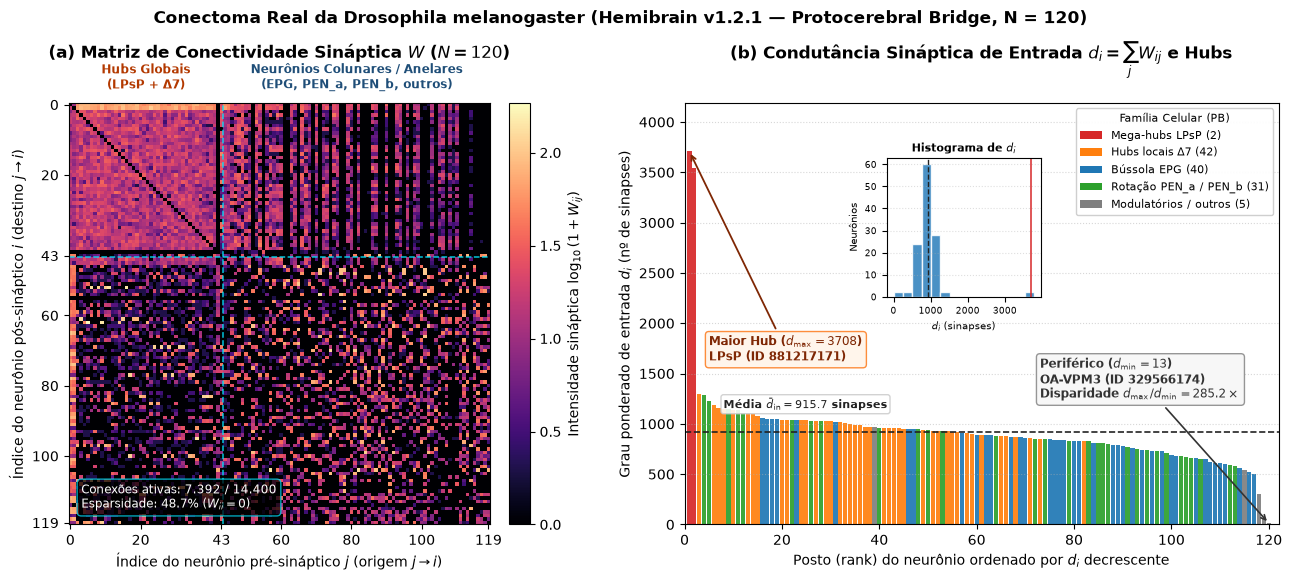

In [3]:
# Célula 3: Geração e Visualização da Figura 1 — Matriz de Conectividade W e Disparidade de Hubs
def _neuron_class_color(neuron_type: str) -> str:
    if neuron_type == "LPsP":
        return "#d62728"  # Vermelho (Mega-hubs LPsP)
    if neuron_type.startswith("Delta7"):
        return "#ff7f0e"  # Laranja (Hubs locais Delta7)
    if neuron_type.startswith("EPG"):
        return "#1f77b4"  # Azul (Neurônios de bússola EPG)
    if neuron_type.startswith("PEN"):
        return "#2ca02c"  # Verde (Neurônios de rotação PEN_a / PEN_b)
    return "#7f7f7f"      # Cinza (Modulatórios / outros)


def plot_connectome_hubs(
    W: np.ndarray,
    neurons: list[dict],
    save_paths: list[str | Path] | str | Path | None = None,
) -> list[Path]:
    if save_paths is None:
        target_paths = [
            Path("results/figures/fig1_connectome_hubs.png"),
            Path("report/fig1_connectome_hubs.png"),
        ]
    elif isinstance(save_paths, (str, Path)):
        target_paths = [Path(save_paths)]
    else:
        target_paths = [Path(p) for p in save_paths]

    fig, (ax1, ax2) = plt.subplots(
        1, 2, figsize=(14.0, 6.2), gridspec_kw={"width_ratios": [1.05, 1.18]}
    )
    fig.subplots_adjust(wspace=0.27, top=0.81, bottom=0.13, left=0.06, right=0.97)

    # Painel (a): Mapa de calor de log10(1 + W_ij)
    W_log = np.log10(1.0 + W)
    im = ax1.imshow(W_log, cmap="magma", aspect="equal", interpolation="nearest", origin="upper")
    cbar = fig.colorbar(im, ax=ax1, fraction=0.046, pad=0.035)
    cbar.set_label(r"Intensidade sináptica $\log_{10}(1 + W_{ij})$", fontsize=10)

    hub_boundary = 43.5
    ax1.axhline(hub_boundary, color="#00e5ff", linestyle="--", linewidth=1.1, alpha=0.85)
    ax1.axvline(hub_boundary, color="#00e5ff", linestyle="--", linewidth=1.1, alpha=0.85)

    ax1.text(
        21.5, -3.5, "Hubs Globais\n(LPsP + Δ7)",
        color="#b33900", fontsize=8.3, fontweight="bold", ha="center", va="bottom", clip_on=False,
    )
    ax1.text(
        81.5, -3.5, "Neurônios Colunares / Anelares\n(EPG, PEN_a, PEN_b, outros)",
        color="#1f4e78", fontsize=8.3, fontweight="bold", ha="center", va="bottom", clip_on=False,
    )

    nnz = int(np.count_nonzero(W))
    sparsity = 100.0 * (1.0 - nnz / (W.shape[0] ** 2))
    ax1.set_title("(a) Matriz de Conectividade Sináptica $W$ ($N = 120$)", fontweight="bold", pad=32)
    ax1.set_xlabel("Índice do neurônio pré-sináptico $j$ (origem $j \\to i$)")
    ax1.set_ylabel("Índice do neurônio pós-sináptico $i$ (destino $j \\to i$)")
    ax1.set_xticks([0, 20, 43, 60, 80, 100, 119])
    ax1.set_yticks([0, 20, 43, 60, 80, 100, 119])
    ax1.text(
        0.03, 0.04,
        f"Conexões ativas: {nnz:,} / 14.400\nEsparsidade: {sparsity:.1f}% ($W_{{ii}} = 0$)".replace(",", "."),
        transform=ax1.transAxes, fontsize=8.5, color="white",
        bbox=dict(boxstyle="round,pad=0.35", facecolor="black", alpha=0.72, edgecolor="#00e5ff"),
    )

    # Painel (b): Perfil de condutância de entrada d_i ordenado + Inset de histograma
    d_in = np.sum(W, axis=1)
    order_din = np.argsort(-d_in)
    d_in_sorted = d_in[order_din]
    ranks = np.arange(1, len(d_in) + 1)
    colors_sorted = [_neuron_class_color(str(neurons[idx]["type"])) for idx in order_din]

    ax2.bar(ranks, d_in_sorted, color=colors_sorted, width=0.88, edgecolor="none", alpha=0.92)
    mean_din = float(np.mean(d_in))
    ax2.axhline(mean_din, color="#222222", linestyle="--", linewidth=1.2)
    ax2.text(
        8.0, mean_din + 240.0, f"Média $\\bar{{d}}_{{\\mathrm{{in}}}} = {mean_din:.1f}$ sinapses",
        fontsize=8.2, fontweight="bold", color="#222222",
        bbox=dict(boxstyle="round,pad=0.22", facecolor="white", alpha=0.88, edgecolor="#cccccc"),
    )

    idx_max, idx_min = int(order_din[0]), int(order_din[-1])
    hub_info, periph_info = neurons[idx_max], neurons[idx_min]
    d_max, d_min = float(d_in[idx_max]), float(d_in[idx_min])

    ax2.annotate(
        f"Maior Hub ($d_{{\\max}} = {int(d_max)}$)\n{hub_info['type']} (ID {hub_info['bodyId']})",
        xy=(1, d_max), xytext=(5, d_max * 0.44),
        fontsize=8.4, fontweight="bold", color="#7f2704",
        arrowprops=dict(arrowstyle="->", color="#7f2704", lw=1.3),
        bbox=dict(boxstyle="round,pad=0.3", facecolor="#fff5eb", edgecolor="#fd8d3c"),
    )
    ax2.annotate(
        f"Periférico ($d_{{\\min}} = {int(d_min)}$)\n{periph_info['type']} (ID {periph_info['bodyId']})\n"
        f"Disparidade $d_{{\\max}}/d_{{\\min}} = {d_max/d_min:.1f}\\times$",
        xy=(120, d_min), xytext=(73, d_max * 0.34),
        fontsize=8.4, fontweight="bold", color="#333333",
        arrowprops=dict(arrowstyle="->", color="#333333", lw=1.2),
        bbox=dict(boxstyle="round,pad=0.3", facecolor="#f7f7f7", edgecolor="#969696"),
    )

    ax2.set_title("(b) Condutância Sináptica de Entrada $d_i = \\sum_j W_{ij}$ e Hubs", fontweight="bold", pad=32)
    ax2.set_xlabel("Posto (rank) do neurônio ordenado por $d_i$ decrescente")
    ax2.set_ylabel("Grau ponderado de entrada $d_i$ (nº de sinapses)")
    ax2.set_xlim(0, 122)
    ax2.set_ylim(0, d_max * 1.13)
    ax2.grid(axis="y", linestyle=":", alpha=0.5)

    legend_elements = [
        Patch(facecolor="#d62728", label="Mega-hubs LPsP (2)"),
        Patch(facecolor="#ff7f0e", label="Hubs locais $\\Delta 7$ (42)"),
        Patch(facecolor="#1f77b4", label="Bússola EPG (40)"),
        Patch(facecolor="#2ca02c", label="Rotação PEN_a / PEN_b (31)"),
        Patch(facecolor="#7f7f7f", label="Modulatórios / outros (5)"),
    ]
    ax2.legend(
        handles=legend_elements, loc="upper right", fontsize=7.9,
        framealpha=0.94, title="Família Celular (PB)", title_fontsize=8.2,
    )

    ax_inset = ax2.inset_axes([0.34, 0.54, 0.26, 0.33])
    bins = np.linspace(0, d_max * 1.02, 16)
    ax_inset.hist(d_in, bins=bins, color="#3182bd", edgecolor="white", alpha=0.88)
    ax_inset.axvline(mean_din, color="#222222", linestyle="--", linewidth=1.0)
    ax_inset.axvline(d_max, color="#d62728", linestyle="-", linewidth=1.1)
    ax_inset.set_title("Histograma de $d_i$", fontsize=7.9, fontweight="bold", pad=4)
    ax_inset.set_xlabel("$d_i$ (sinapses)", fontsize=7.3)
    ax_inset.set_ylabel("Neurônios", fontsize=7.3)
    ax_inset.tick_params(labelsize=6.8)
    ax_inset.grid(axis="y", linestyle=":", alpha=0.4)

    fig.suptitle(
        "Conectoma Real da Drosophila melanogaster (Hemibrain v1.2.1 — Protocerebral Bridge, N = 120)",
        fontsize=12.5, fontweight="bold", y=0.96,
    )

    saved_paths = []
    for out_file in target_paths:
        out_file.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(out_file, dpi=300)
        saved_paths.append(out_file)

    plt.show()
    return saved_paths


fig1_paths = plot_connectome_hubs(
    W_N120,
    neurons_N120,
    save_paths=[
        "results/figures/fig1_connectome_hubs.png",
        "report/fig1_connectome_hubs.png",
    ],
)
print(f"Figura 1 salva em alta resolução (300 DPI): {fig1_paths[0]}")